# Intelligent Traffic & Safety Analytics System

A complete perception-to-insight video analytics pipeline: detection, multi-object tracking, directional counting, rule-based anomaly detection, movement heatmaps, and an automated dashboard report — built entirely from pretrained components, with no training and no special hardware.

**Real-world use cases:** smart-city traffic monitoring, pedestrian safety analysis, retail/venue occupancy and flow analytics, automated surveillance reporting.

**System architecture**

| Stage | Component |
|---|---|
| Input | Pre-recorded video (auto-downloaded sample clip, a YouTube URL, or a local file) |
| Perception | **YOLO26n** (Ultralytics' current nano detector, pretrained on COCO) |
| Association | **ByteTrack** (built into Ultralytics) — gives every detection a stable ID across frames |
| Analytics layer | Custom logic: per-class directional counting, movement heatmap accumulation, event logging |
| Anomaly layer | Custom rule-based checks on top of the tracked trajectories: **wrong-direction movement**, **loitering**, **stopped/congested objects** |
| Learned layer | A small **trained** neural network (PyTorch) that classifies object type from geometry + motion alone, with a real train/test split, loss curve, and accuracy |
| Segmentation | **YOLO26n-seg** — a second pretrained deep learning model, run on sample frames to show pixel-precise instance masks alongside the boxes used everywhere else |
| Output | Annotated video, two CSV event logs, a saved heatmap image, a 4-panel analytics dashboard, a training report, and a segmentation comparison figure |

**Why this counts as a substantial system, not just "running a pretrained model":** the detector and tracker are off-the-shelf, but everything from that point on — the counting rules, the three anomaly detectors, the heatmap accumulator, and the reporting layer — is original logic built on top of their raw output. That analytics layer is the actual engineering content of the project.

No model is trained here. YOLO26n ships pretrained on COCO (80 everyday classes). Because nothing is trained, the whole notebook runs in a single pass, start to finish, with no repeated re-running needed to get a full result set.

**This version is built to run unattended on Google Colab or locally**: video sourcing defaults to a reliable, purpose-built sample clip (no YouTube dependency required), and the live preview window automatically disables itself if the environment doesn't support one, instead of stopping the run.

**On the "no training" requirement:** the detector (YOLO26n) is pretrained and never fine-tuned — that constraint hasn't changed. Section 6 adds something different: a separate, tiny classifier trained from scratch, in seconds, on simple numbers this notebook already collects (box size, shape, speed) rather than on images. It's a genuine training run — real gradient descent, a real loss curve, a real held-out test score — just on a small enough model and dataset that "training" still means seconds, not hours.

## 1. Install & Import Libraries

`ultralytics` (YOLO26n detector + ByteTrack tracker), `lap` (required by the tracker's ID-assignment step — installing it up front avoids a "restart runtime" warning on first use), `opencv-python` (video I/O, heatmap drawing), `supervision` (provides ready-made sample video clips, avoiding any dependency on YouTube), `yt-dlp` (only needed if you specifically want a custom YouTube clip instead), `matplotlib` (dashboard). `csv` and `collections` are standard library. `torch` (PyTorch) comes in as an `ultralytics` dependency already — no extra install — and is used in Section 6 to train the small classifier. None of this needs a GPU.

In [1]:
!pip install -q ultralytics lap opencv-python supervision yt-dlp matplotlib

import os
import csv
import time
from collections import defaultdict, deque, Counter

import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from ultralytics import YOLO

try:
    import google.colab
    from google.colab.patches import cv2_imshow
    from IPython.display import clear_output
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

print("Libraries ready.", "(Google Colab detected)" if IN_COLAB else "(local environment)")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.5/45.5 kB 765.3 kB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 183.8/183.8 kB 2.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.9/79.9 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 15.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 29.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 280.2/280.2 kB 13.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 35.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.2/53.2 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 102.7/102.7 kB 6.0 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/

## 2. Get a Video

Three options — set `VIDEO_SOURCE_MODE` to one of `"sample"`, `"youtube"`, or `"local"`:

- **`"sample"` (default, most reliable):** auto-downloads a ready-made clip from `supervision`'s asset library — a small, purpose-built collection of demo videos (traffic, pedestrians, a market square, a subway) hosted directly by its maintainers (Roboflow), not YouTube. No sign-in checks, no bot detection, works the same on Colab or locally. Change `SAMPLE_VIDEO_ASSET` to try a different scene.
- **`"youtube"`:** paste a URL into `YOUTUBE_URL` to use a specific custom clip instead. YouTube occasionally blocks automated downloads with a *"Sign in to confirm you're not a bot"* error, especially from cloud/Colab IPs — if that happens, the error message below explains the options, but switching back to `"sample"` is the fastest fix.
- **`"local"`:** point `LOCAL_VIDEO_PATH` at any video file already available from any source.

Whichever mode is used, the rest of the notebook only ever looks at `LOCAL_VIDEO_PATH` — everything after this cell is identical regardless of where the video came from.

In [3]:
VIDEO_SOURCE_MODE = "sample"   # "sample", "youtube", or "local"

SAMPLE_VIDEO_ASSET = "vehicles.mp4"   # also try: "people-walking.mp4", "market-square.mp4", "subway.mp4", "grocery-store.mp4"
YOUTUBE_URL = "https://youtu.be/w0S6UyK4UFI"   # used only if VIDEO_SOURCE_MODE = "youtube" - swap for any other clip freely
LOCAL_VIDEO_PATH = "sample_video.mp4"  # used only if VIDEO_SOURCE_MODE = "local"; also where downloads are saved

if VIDEO_SOURCE_MODE == "sample":
    from supervision.assets import download_assets
    print(f"Downloading ready-made sample clip: {SAMPLE_VIDEO_ASSET} ...")
    try:
        LOCAL_VIDEO_PATH = download_assets(SAMPLE_VIDEO_ASSET)
        print(f"Ready: '{LOCAL_VIDEO_PATH}'")
    except Exception as e:
        raise SystemExit(
            f"Could not download the sample clip ({e}).\n"
            f"Check the internet connection, or switch to VIDEO_SOURCE_MODE = \"local\" "
            f"and point LOCAL_VIDEO_PATH at any video file you already have."
        )

elif VIDEO_SOURCE_MODE == "youtube":
    if not YOUTUBE_URL:
        raise SystemExit('VIDEO_SOURCE_MODE is "youtube" but YOUTUBE_URL is empty - paste a video URL in.')
    print("Downloading from YouTube...")
    try:
        import yt_dlp
        ydl_opts = {
            "format": "best[height<=480]/best",
            "outtmpl": LOCAL_VIDEO_PATH,
            "quiet": True,
            "no_warnings": True,
        }
        with yt_dlp.YoutubeDL(ydl_opts) as ydl:
            ydl.download([YOUTUBE_URL])
        print(f"Downloaded to '{LOCAL_VIDEO_PATH}'")
    except Exception as e:
        err_msg = str(e)
        bot_check_hint = ""
        if "not a bot" in err_msg or "Sign in" in err_msg:
            bot_check_hint = (
                "\nThis specific error means YouTube is blocking automated downloads from this connection "
                "(common on Colab/cloud IPs, and can vary between runs). The fastest fix: set "
                'VIDEO_SOURCE_MODE = "sample" above and rerun - that path does not use YouTube at all.'
            )
        raise SystemExit(
            f"Automatic download failed ({e}).{bot_check_hint}\n"
            f"Other options: 'pip install -U yt-dlp' and retry, or download manually from a terminal:\n"
            f'  yt-dlp -f "best[height<=480]" -o {LOCAL_VIDEO_PATH} "{YOUTUBE_URL}"'
        )

elif not os.path.exists(LOCAL_VIDEO_PATH):
    raise SystemExit(
        f"VIDEO_SOURCE_MODE is \"local\" but no file was found at '{LOCAL_VIDEO_PATH}'. "
        f"Place a video there, or switch VIDEO_SOURCE_MODE to \"sample\"."
    )
else:
    print(f"Using existing local file: '{LOCAL_VIDEO_PATH}'")

[2026-08-01 08:19:09] [INFO] supervision.assets.downloader - Downloading vehicles.mp4 assets


  0%|          | 0/35345757 [00:00<?, ?it/s]

Ready: 'vehicles.mp4'


## 3. Configuration

**Detection & counting**
- `CLASSES_TO_COUNT` — COCO ids to detect/track/count. Defaults to people and vehicles together (`0, 2, 3, 5, 7`).
- `LINE_ORIENTATION` / `LINE_POSITION` — the virtual counting line. `"horizontal"` suits footage where motion is mostly up/down in frame; `"vertical"` suits left/right motion. `LINE_POSITION` is a fraction (0-1) of the frame's height or width.

**Anomaly detection** (each rule can be switched off independently)
- `DETECT_WRONG_WAY` — flags a crossing that goes against the direction most other objects are moving, once enough crossings exist to establish which direction is "normal" (`WRONG_WAY_MIN_BASELINE_CROSSINGS`).
- `DETECT_LOITERING` — flags an object tracked continuously for longer than `LOITER_THRESHOLD_SECONDS` without ever crossing the line.
- `DETECT_STOPPED` — flags an object whose recent movement (over `STOPPED_HISTORY_FRAMES` frames) is slower than `STOPPED_THRESHOLD_PX_PER_SEC`, suggesting it has stopped or traffic is congested.

**Heatmap**
- `HEATMAP_UPDATE_EVERY` recomputes the colored overlay only every N frames as a CPU-saving measure — the underlying accumulated data is still updated every frame.

**Display**
- `SHOW_LIVE_PREVIEW` — shows the video live while it processes, so you can watch detections happen frame by frame. Locally this opens a normal OpenCV window (press `q` to stop early); on Google Colab it's detected automatically and uses `cv2_imshow` together with `clear_output(wait=True)`, so each new frame replaces the last instead of stacking up — only the current frame is ever kept in the notebook's output, so this stays lightweight no matter how long the video is.
- `PREVIEW_EVERY_N_FRAMES` — how often the preview updates (`1` = every frame). This only affects what you watch live; `output_analyzed.mp4` always contains every processed frame regardless, so raising this to 2 or 3 is a safe way to speed things up if the live view feels slow without losing anything from the saved result.

In [4]:
MODEL_NAME = "yolo26n.pt"            # Ultralytics' current nano model - pretrained, downloads automatically (~5 MB)
CONF_THRESHOLD = 0.4
CLASSES_TO_COUNT = [0, 2, 3, 5, 7]    # COCO ids: 0=person, 2=car, 3=motorcycle, 5=bus, 7=truck
LINE_ORIENTATION = "horizontal"       # "horizontal" or "vertical"
LINE_POSITION = 0.5                   # fraction of frame height (horizontal) or width (vertical)

OUTPUT_VIDEO_PATH = "output_analyzed.mp4"
LOG_CSV_PATH = "crossing_events.csv"
ANOMALY_CSV_PATH = "anomaly_events.csv"
DASHBOARD_PATH = "dashboard.png"

HEATMAP_ENABLED = True
HEATMAP_OUTPUT_PATH = "heatmap_final.png"
HEATMAP_ALPHA = 0.35
HEATMAP_RADIUS = 20
HEATMAP_UPDATE_EVERY = 5

ANOMALY_DETECTION_ENABLED = True
DETECT_WRONG_WAY = True
DETECT_LOITERING = True
DETECT_STOPPED = True
WRONG_WAY_MIN_BASELINE_CROSSINGS = 5
LOITER_THRESHOLD_SECONDS = 8.0
STOPPED_THRESHOLD_PX_PER_SEC = 5.0
STOPPED_HISTORY_FRAMES = 15

SHOW_LIVE_PREVIEW = True
PREVIEW_EVERY_N_FRAMES = 1   # show every frame (1) for the fullest live view; raise to 2-3 if it feels slow

TRAIN_CLASSIFIER = True       # trains a tiny object-type classifier in Section 6 (seconds, not hours)
CLASSIFIER_EPOCHS = 60
CLASSIFIER_TEST_SPLIT = 0.2
MIN_SAMPLES_TO_TRAIN = 20     # skip training with a clear message below this
CLASSIFIER_CHART_PATH = "classifier_training.png"


## 4. Detection, Tracking, Counting, Anomaly Detection & Heatmap

The core loop, for every frame:

1. Detect + track all configured classes (YOLO26n + ByteTrack).
2. For each tracked object: check if it just crossed the counting line (per class + direction) → log the event → if the direction goes against the established majority, flag **wrong-way**.
3. Update how long the object has been tracked without crossing → if past the threshold, flag **loitering**.
4. Update its recent-position history → if its effective speed drops too low, flag **stopped**.
5. Accumulate its position into the heatmap.
6. Draw everything (boxes — orange if flagged, green otherwise — the line, live counts, and the heatmap overlay), write the frame to the output video, and try to show it live (skipped automatically if unsupported).

Every anomaly rule reuses the same tracking IDs that make counting possible — without stable IDs, none of the "how long has this been here" or "which direction did it just cross" logic would be reliable.

**Run this cell.** If a live preview window opens, press `q` in it to stop early; otherwise it runs to completion on its own.

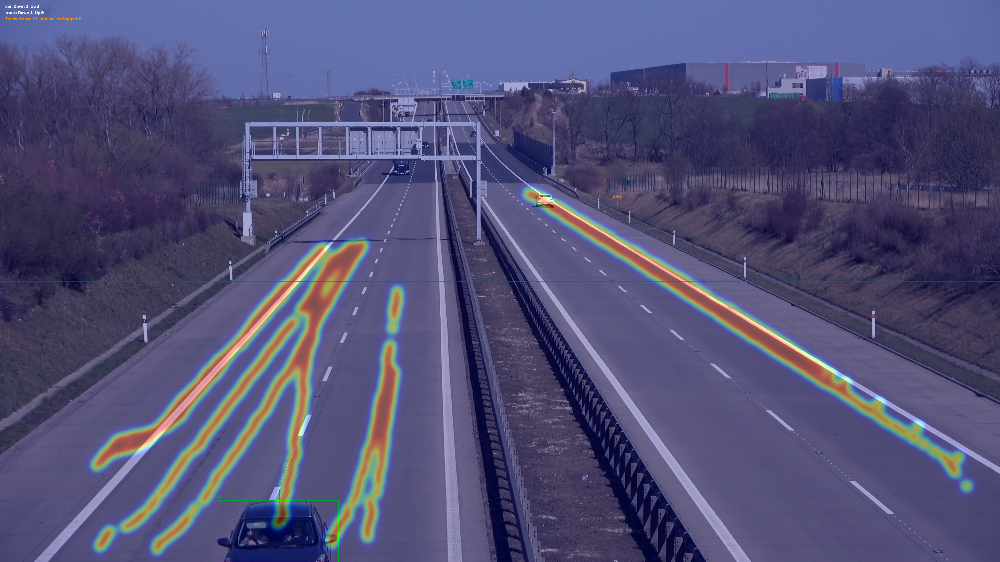

Saved annotated video to: output_analyzed.mp4
Saved crossing log to: crossing_events.csv (7 events)
Saved anomaly log to: anomaly_events.csv (0 events)
Saved heatmap image to: heatmap_final.png

Crossing totals:
  car          Down:    3   Up:    3
  truck        Down:    1   Up:    0


In [5]:
def main():
    global SHOW_LIVE_PREVIEW
    model = YOLO(MODEL_NAME)

    cap = cv2.VideoCapture(LOCAL_VIDEO_PATH)
    if not cap.isOpened():
        raise SystemExit(f"Could not open video: {LOCAL_VIDEO_PATH!r}")

    fps = cap.get(cv2.CAP_PROP_FPS)
    if not fps or fps <= 0:
        fps = 30.0
    frame_w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)) or 640
    frame_h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)) or 480
    wait_ms = max(1, int(1000 / fps))

    line_coord = int(frame_h * LINE_POSITION) if LINE_ORIENTATION == "horizontal" else int(frame_w * LINE_POSITION)
    label_a = "Down" if LINE_ORIENTATION == "horizontal" else "Right"
    label_b = "Up" if LINE_ORIENTATION == "horizontal" else "Left"

    fourcc = cv2.VideoWriter_fourcc(*"mp4v")
    writer = cv2.VideoWriter(OUTPUT_VIDEO_PATH, fourcc, fps, (frame_w, frame_h))

    track_last_pos = {}
    track_first_seen = {}
    track_pos_history = {}
    track_flags = defaultdict(set)

    counts = defaultdict(lambda: {"a_to_b": 0, "b_to_a": 0})
    log_rows = []
    anomaly_log = []
    classifier_rows = []

    heatmap = np.zeros((frame_h, frame_w), dtype=np.float32)
    cached_heatmap_overlay = None
    frame_idx = 0

    try:
        while cap.isOpened():
            ret, frame = cap.read()
            if not ret:
                break

            results = model.track(frame, persist=True, conf=CONF_THRESHOLD, classes=CLASSES_TO_COUNT, verbose=False)
            r = results[0]

            if r.boxes is not None and r.boxes.id is not None:
                boxes = r.boxes.xywh.cpu().numpy()
                ids = r.boxes.id.int().cpu().tolist()
                clss = r.boxes.cls.int().cpu().tolist()

                for (cx, cy, bw, bh), tid, cls_id in zip(boxes, ids, clss):
                    cls_name = model.names[cls_id]
                    coord = cy if LINE_ORIENTATION == "horizontal" else cx
                    t = round(frame_idx / fps, 2)

                    # --- directional line-crossing count ---
                    if tid in track_last_pos:
                        prev = track_last_pos[tid]
                        crossed_dir = None
                        if prev < line_coord <= coord:
                            counts[cls_name]["a_to_b"] += 1
                            crossed_dir = label_a
                        elif prev > line_coord >= coord:
                            counts[cls_name]["b_to_a"] += 1
                            crossed_dir = label_b

                        if crossed_dir:
                            log_rows.append({"frame": frame_idx, "time_sec": t, "track_id": tid,
                                              "class": cls_name, "direction": crossed_dir})

                            if ANOMALY_DETECTION_ENABLED and DETECT_WRONG_WAY:
                                total_a = sum(d["a_to_b"] for d in counts.values())
                                total_b = sum(d["b_to_a"] for d in counts.values())
                                if total_a + total_b >= WRONG_WAY_MIN_BASELINE_CROSSINGS:
                                    majority_dir = label_a if total_a > total_b else label_b
                                    if crossed_dir != majority_dir:
                                        track_flags[tid].add("wrong_way")
                                        anomaly_log.append({"frame": frame_idx, "time_sec": t, "track_id": tid,
                                                             "class": cls_name, "type": "wrong_way",
                                                             "detail": f"crossed {crossed_dir}, majority is {majority_dir}"})
                    track_last_pos[tid] = coord

                    # --- anomaly bookkeeping: loitering + stopped ---
                    if tid not in track_first_seen:
                        track_first_seen[tid] = frame_idx
                    if tid not in track_pos_history:
                        track_pos_history[tid] = deque(maxlen=STOPPED_HISTORY_FRAMES)
                    track_pos_history[tid].append((frame_idx, cx, cy))

                    if ANOMALY_DETECTION_ENABLED and DETECT_LOITERING:
                        dwell = (frame_idx - track_first_seen[tid]) / fps
                        if dwell >= LOITER_THRESHOLD_SECONDS and "loiter" not in track_flags[tid]:
                            track_flags[tid].add("loiter")
                            anomaly_log.append({"frame": frame_idx, "time_sec": t, "track_id": tid,
                                                 "class": cls_name, "type": "loitering",
                                                 "detail": f"tracked {dwell:.1f}s without crossing"})

                    if ANOMALY_DETECTION_ENABLED and DETECT_STOPPED:
                        hist = track_pos_history[tid]
                        if len(hist) == hist.maxlen:
                            f0, x0, y0 = hist[0]
                            f1, x1, y1 = hist[-1]
                            dt = (f1 - f0) / fps
                            if dt > 0:
                                speed = ((x1 - x0) ** 2 + (y1 - y0) ** 2) ** 0.5 / dt
                                if speed < STOPPED_THRESHOLD_PX_PER_SEC and "stopped" not in track_flags[tid]:
                                    track_flags[tid].add("stopped")
                                    anomaly_log.append({"frame": frame_idx, "time_sec": t, "track_id": tid,
                                                         "class": cls_name, "type": "stopped",
                                                         "detail": f"speed ~{speed:.1f}px/s"})

                    if HEATMAP_ENABLED:
                        cv2.circle(heatmap, (int(cx), int(cy)), HEATMAP_RADIUS, 1.0, -1)

                    # --- feature row for the Section 6 classifier (geometry + motion only, no pixels) ---
                    if TRAIN_CLASSIFIER:
                        hist = track_pos_history[tid]
                        if len(hist) >= 2:
                            f0, x0, y0 = hist[0]
                            f1, x1, y1 = hist[-1]
                            dt = (f1 - f0) / fps
                            speed_est = (((x1 - x0) ** 2 + (y1 - y0) ** 2) ** 0.5 / dt) if dt > 0 else 0.0
                        else:
                            speed_est = 0.0
                        classifier_rows.append({
                            "width_norm": bw / frame_w,
                            "height_norm": bh / frame_h,
                            "aspect_ratio": bw / max(bh, 1e-6),
                            "speed_norm": speed_est / frame_w,
                            "label": cls_name,
                        })

                    # --- drawing ---
                    flagged = bool(track_flags[tid])
                    box_color = (0, 140, 255) if flagged else (0, 255, 0)
                    x1, y1 = int(cx - bw / 2), int(cy - bh / 2)
                    x2, y2 = int(cx + bw / 2), int(cy + bh / 2)
                    cv2.rectangle(frame, (x1, y1), (x2, y2), box_color, 2)
                    tag = f" [{'/'.join(sorted(track_flags[tid]))}]" if flagged else ""
                    cv2.putText(frame, f"{cls_name} #{tid}{tag}", (x1, max(y1 - 8, 10)),
                                cv2.FONT_HERSHEY_SIMPLEX, 0.5, box_color, 1)

            if HEATMAP_ENABLED and heatmap.max() > 0:
                if cached_heatmap_overlay is None or frame_idx % HEATMAP_UPDATE_EVERY == 0:
                    blurred = cv2.GaussianBlur(heatmap, (0, 0), sigmaX=15, sigmaY=15)
                    norm = cv2.normalize(blurred, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
                    cached_heatmap_overlay = cv2.applyColorMap(norm, cv2.COLORMAP_JET)
                frame = cv2.addWeighted(frame, 1 - HEATMAP_ALPHA, cached_heatmap_overlay, HEATMAP_ALPHA, 0)

            if LINE_ORIENTATION == "horizontal":
                cv2.line(frame, (0, line_coord), (frame_w, line_coord), (0, 0, 255), 2)
            else:
                cv2.line(frame, (line_coord, 0), (line_coord, frame_h), (0, 0, 255), 2)

            y_off = 30
            for cls_name, d in counts.items():
                cv2.putText(frame, f"{cls_name}: {label_a} {d['a_to_b']}  {label_b} {d['b_to_a']}",
                            (20, y_off), cv2.FONT_HERSHEY_SIMPLEX, 0.55, (255, 255, 255), 2)
                y_off += 24
            cv2.putText(frame, f"Tracked now: {len(track_last_pos)}   Anomalies flagged: {len(anomaly_log)}",
                        (20, y_off), cv2.FONT_HERSHEY_SIMPLEX, 0.55, (0, 140, 255), 2)

            writer.write(frame)

            if SHOW_LIVE_PREVIEW:
                if IN_COLAB:
                    if frame_idx % PREVIEW_EVERY_N_FRAMES == 0:
                        clear_output(wait=True)
                        cv2_imshow(frame)
                else:
                    try:
                        cv2.imshow("Traffic & Safety Analytics - press q to quit", frame)
                        if cv2.waitKey(wait_ms) & 0xFF == ord('q'):
                            break
                    except Exception:
                        SHOW_LIVE_PREVIEW = False
                        print("No live preview available in this environment - "
                              "continuing without it. The annotated video is still being saved normally.")

            frame_idx += 1
    finally:
        cap.release()
        writer.release()
        if SHOW_LIVE_PREVIEW and not IN_COLAB:
            cv2.destroyAllWindows()

        with open(LOG_CSV_PATH, "w", newline="") as f:
            w = csv.DictWriter(f, fieldnames=["frame", "time_sec", "track_id", "class", "direction"])
            w.writeheader()
            w.writerows(log_rows)

        with open(ANOMALY_CSV_PATH, "w", newline="") as f:
            w = csv.DictWriter(f, fieldnames=["frame", "time_sec", "track_id", "class", "type", "detail"])
            w.writeheader()
            w.writerows(anomaly_log)

        if HEATMAP_ENABLED and heatmap.max() > 0:
            blurred = cv2.GaussianBlur(heatmap, (0, 0), sigmaX=15, sigmaY=15)
            norm = cv2.normalize(blurred, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
            cv2.imwrite(HEATMAP_OUTPUT_PATH, cv2.applyColorMap(norm, cv2.COLORMAP_JET))

        print(f"Saved annotated video to: {OUTPUT_VIDEO_PATH}")
        print(f"Saved crossing log to: {LOG_CSV_PATH} ({len(log_rows)} events)")
        print(f"Saved anomaly log to: {ANOMALY_CSV_PATH} ({len(anomaly_log)} events)")
        if HEATMAP_ENABLED:
            print(f"Saved heatmap image to: {HEATMAP_OUTPUT_PATH}")
        print("\nCrossing totals:")
        for cls_name, d in counts.items():
            print(f"  {cls_name:12s} {label_a}: {d['a_to_b']:4d}   {label_b}: {d['b_to_a']:4d}")
        if anomaly_log:
            print("\nAnomaly totals:")
            for atype, c in Counter(e["type"] for e in anomaly_log).items():
                print(f"  {atype}: {c}")

    return counts, log_rows, anomaly_log, classifier_rows


counts, log_rows, anomaly_log, classifier_rows = main()

## 5. Analytics Dashboard

Builds a single 4-panel report from the results above: per-class directional counts, cumulative flow over time, anomaly-type breakdown, and the movement heatmap — saved together as `dashboard.png`, ready to drop into a report or slide deck.

=== Crossing Summary ===
Total Down: 4   Total Up: 3   Total events: 7

  car          Down:    3   Up:    3
  truck        Down:    1   Up:    0

=== Anomaly Summary ===
  No anomalies flagged.


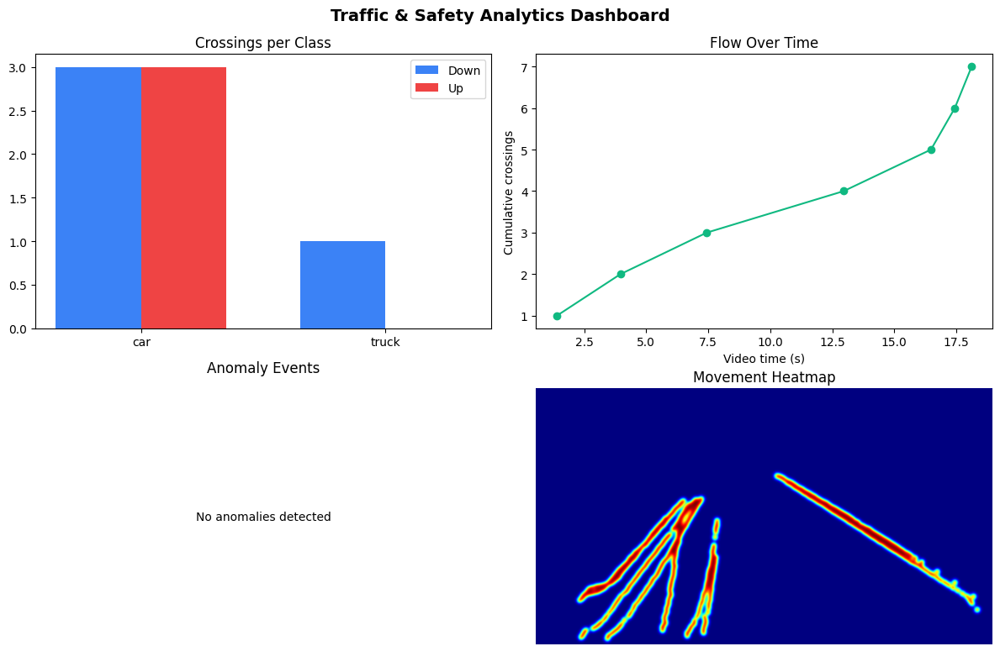


Saved dashboard to: dashboard.png


In [6]:
label_a = "Down" if LINE_ORIENTATION == "horizontal" else "Right"
label_b = "Up" if LINE_ORIENTATION == "horizontal" else "Left"

total_a = sum(d["a_to_b"] for d in counts.values())
total_b = sum(d["b_to_a"] for d in counts.values())
print("=== Crossing Summary ===")
print(f"Total {label_a}: {total_a}   Total {label_b}: {total_b}   Total events: {len(log_rows)}\n")
for cls_name, d in counts.items():
    print(f"  {cls_name:12s} {label_a}: {d['a_to_b']:4d}   {label_b}: {d['b_to_a']:4d}")

print("\n=== Anomaly Summary ===")
if anomaly_log:
    for atype, c in Counter(e["type"] for e in anomaly_log).items():
        print(f"  {atype:12s}: {c}")
else:
    print("  No anomalies flagged.")

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
fig.suptitle("Traffic & Safety Analytics Dashboard", fontsize=14, fontweight="bold")

ax = axes[0, 0]
if counts:
    class_names = list(counts.keys())
    a_vals = [counts[c]["a_to_b"] for c in class_names]
    b_vals = [counts[c]["b_to_a"] for c in class_names]
    x = np.arange(len(class_names))
    width = 0.35
    ax.bar(x - width / 2, a_vals, width, label=label_a, color="#3B82F6")
    ax.bar(x + width / 2, b_vals, width, label=label_b, color="#EF4444")
    ax.set_xticks(x)
    ax.set_xticklabels(class_names)
    ax.legend()
else:
    ax.text(0.5, 0.5, "No crossings recorded", ha="center", va="center")
    ax.axis("off")
ax.set_title("Crossings per Class")

ax = axes[0, 1]
if log_rows:
    times = [row["time_sec"] for row in log_rows]
    cumulative = list(range(1, len(times) + 1))
    ax.plot(times, cumulative, marker="o", color="#10B981")
    ax.set_xlabel("Video time (s)")
    ax.set_ylabel("Cumulative crossings")
else:
    ax.text(0.5, 0.5, "No crossings recorded", ha="center", va="center")
    ax.axis("off")
ax.set_title("Flow Over Time")

ax = axes[1, 0]
if anomaly_log:
    type_counts = Counter(e["type"] for e in anomaly_log)
    ax.bar(list(type_counts.keys()), list(type_counts.values()), color="#F59E0B")
    ax.set_ylabel("Count")
else:
    ax.text(0.5, 0.5, "No anomalies detected", ha="center", va="center")
    ax.axis("off")
ax.set_title("Anomaly Events")

ax = axes[1, 1]
if HEATMAP_ENABLED and os.path.exists(HEATMAP_OUTPUT_PATH):
    hm = cv2.cvtColor(cv2.imread(HEATMAP_OUTPUT_PATH), cv2.COLOR_BGR2RGB)
    ax.imshow(hm)
else:
    ax.text(0.5, 0.5, "Heatmap disabled", ha="center", va="center")
ax.set_title("Movement Heatmap")
ax.axis("off")

fig.tight_layout()
fig.savefig(DASHBOARD_PATH, dpi=120)
plt.show()
print(f"\nSaved dashboard to: {DASHBOARD_PATH}")

## 6. A Trained Classifier — Object Type from Geometry + Motion

Everything so far uses YOLO26n's own pixel-based classification. This section asks a narrower, different question: **without looking at any pixels at all**, just from a box's size, shape, and how fast it's moving, can a small trained network still tell a person from a car?

- **Features (4 numbers per sample):** normalized width, normalized height, aspect ratio, normalized speed — all values this notebook already computes while tracking, no new detection needed.
- **Labels:** YOLO26n's own class for that object. This is *not* independent, human-verified ground truth — it's "can simple geometry alone recover what the pretrained model already knows from pixels?" A fair, honestly-stated comparison, not a claim of a better classifier.
- **Samples:** one row per tracked object *per frame* it's seen in, so a busier or longer video produces more training data automatically. Rows from the same object across nearby frames are correlated, not fully independent — noted again in Limitations.
- **Model:** a genuinely tiny network (`4 → 16 → n_classes`, one hidden layer, ReLU), trained with real backpropagation (`Adam`, cross-entropy loss) for a fixed number of epochs on an 80/20 train/test split.

This is real training — a real loss curve, a real held-out test score — just scoped so small (tabular features, not images; tens of thousands of parameters, not millions) that it finishes in a couple of seconds on CPU rather than hours on a GPU.

Classes: ['bus', 'car', 'truck']
Samples: 979 total -> 783 train / 196 test
Trained 60 epochs in 0.10 seconds
Loss: 1.307 -> 0.333
Train accuracy: 80.7%   Test accuracy: 82.7%


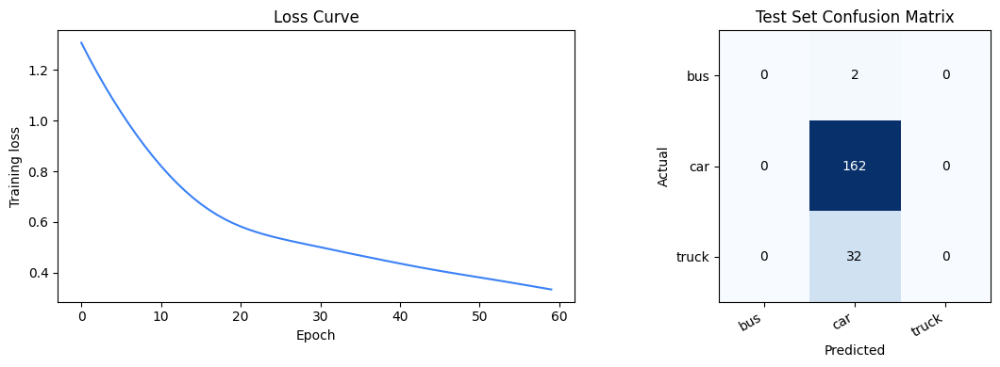


Saved training chart to: classifier_training.png


In [7]:
FEATURE_COLS = ["width_norm", "height_norm", "aspect_ratio", "speed_norm"]

if not TRAIN_CLASSIFIER:
    print("TRAIN_CLASSIFIER is False - skipping Section 6.")
elif len(classifier_rows) < MIN_SAMPLES_TO_TRAIN:
    print(f"Only {len(classifier_rows)} samples collected (need >= {MIN_SAMPLES_TO_TRAIN}). "
          f"Try a longer or busier video, or lower MIN_SAMPLES_TO_TRAIN in Section 3.")
else:
    class_names_present = sorted(set(r["label"] for r in classifier_rows))
    if len(class_names_present) < 2:
        print(f"Only one class present ({class_names_present[0]!r}) in this video - need at least 2 "
              f"to train a classifier between them. Try a clip with a mix of people and vehicles.")
    else:
        label_to_idx = {c: i for i, c in enumerate(class_names_present)}
        X = np.array([[r[c] for c in FEATURE_COLS] for r in classifier_rows], dtype=np.float32)
        y = np.array([label_to_idx[r["label"]] for r in classifier_rows], dtype=np.int64)

        rng = np.random.default_rng(42)
        perm = rng.permutation(len(X))
        split = int(len(X) * (1 - CLASSIFIER_TEST_SPLIT))
        train_idx, test_idx = perm[:split], perm[split:]
        X_train, y_train = torch.tensor(X[train_idx]), torch.tensor(y[train_idx])
        X_test, y_test = torch.tensor(X[test_idx]), torch.tensor(y[test_idx])

        class TinyClassifier(nn.Module):
            def __init__(self, n_features, n_classes):
                super().__init__()
                self.net = nn.Sequential(nn.Linear(n_features, 16), nn.ReLU(), nn.Linear(16, n_classes))

            def forward(self, x):
                return self.net(x)

        torch.manual_seed(0)
        clf_model = TinyClassifier(len(FEATURE_COLS), len(class_names_present))
        optimizer = torch.optim.Adam(clf_model.parameters(), lr=0.01)
        criterion = nn.CrossEntropyLoss()

        t0 = time.time()
        loss_history = []
        for epoch in range(CLASSIFIER_EPOCHS):
            optimizer.zero_grad()
            out = clf_model(X_train)
            loss = criterion(out, y_train)
            loss.backward()
            optimizer.step()
            loss_history.append(loss.item())
        train_seconds = time.time() - t0

        clf_model.eval()
        with torch.no_grad():
            train_acc = (clf_model(X_train).argmax(1) == y_train).float().mean().item()
            test_preds_t = clf_model(X_test).argmax(1)
            test_acc = (test_preds_t == y_test).float().mean().item() if len(X_test) else float("nan")

        print(f"Classes: {class_names_present}")
        print(f"Samples: {len(X)} total -> {len(X_train)} train / {len(X_test)} test")
        print(f"Trained {CLASSIFIER_EPOCHS} epochs in {train_seconds:.2f} seconds")
        print(f"Loss: {loss_history[0]:.3f} -> {loss_history[-1]:.3f}")
        print(f"Train accuracy: {train_acc:.1%}   Test accuracy: {test_acc:.1%}")

        fig, axes = plt.subplots(1, 2, figsize=(12, 4))

        axes[0].plot(loss_history, color="#3B82F6")
        axes[0].set_xlabel("Epoch")
        axes[0].set_ylabel("Training loss")
        axes[0].set_title("Loss Curve")

        n_classes = len(class_names_present)
        test_preds = test_preds_t.numpy() if len(X_test) else np.array([], dtype=int)
        conf = np.zeros((n_classes, n_classes), dtype=int)
        for t_true, t_pred in zip(y[test_idx], test_preds):
            conf[t_true, t_pred] += 1
        axes[1].imshow(conf, cmap="Blues")
        axes[1].set_xticks(range(n_classes))
        axes[1].set_xticklabels(class_names_present, rotation=30, ha="right")
        axes[1].set_yticks(range(n_classes))
        axes[1].set_yticklabels(class_names_present)
        axes[1].set_xlabel("Predicted")
        axes[1].set_ylabel("Actual")
        axes[1].set_title("Test Set Confusion Matrix")
        for i in range(n_classes):
            for j in range(n_classes):
                axes[1].text(j, i, str(conf[i, j]), ha="center", va="center",
                             color="white" if conf[i, j] > conf.max() / 2 else "black")

        fig.tight_layout()
        fig.savefig(CLASSIFIER_CHART_PATH, dpi=120)
        plt.show()
        print(f"\nSaved training chart to: {CLASSIFIER_CHART_PATH}")

## 7. Instance Segmentation — A Second Deep Learning Model

Everything up to here uses **object detection**: a box around each object ("a car is roughly inside this rectangle"). This section adds **instance segmentation**: a pixel-precise mask for each object ("these exact pixels are the car, and no others"), using a second pretrained deep learning model, **YOLO26n-seg** — the segmentation variant of the exact same model family, same library, same one-line loading pattern.

**Why this runs on a few sample frames instead of the whole video:** segmentation is noticeably heavier per frame than detection alone (predicting a mask, not just four box coordinates), and the main pipeline (Sections 1-6) already tracks, counts, and flags anomalies correctly using boxes — masks wouldn't change any of those results, only add cost. So rather than slow down or risk the already-verified tracking loop, this section demonstrates segmentation on its own, independently, on a handful of frames pulled evenly from the same video — genuinely fast, and a clean, separate proof that the technique works.

**Detection vs. segmentation, concretely:** a bounding box around a person walking close to a lamp-post includes a slice of the lamp-post too; a segmentation mask contains only the pixels that are actually the person. For counting people crossing a line, that extra precision doesn't change the answer — which is exactly why Sections 1-6 use the faster, simpler box-based model, and this section exists to show the more expensive alternative deliberately, not by default.

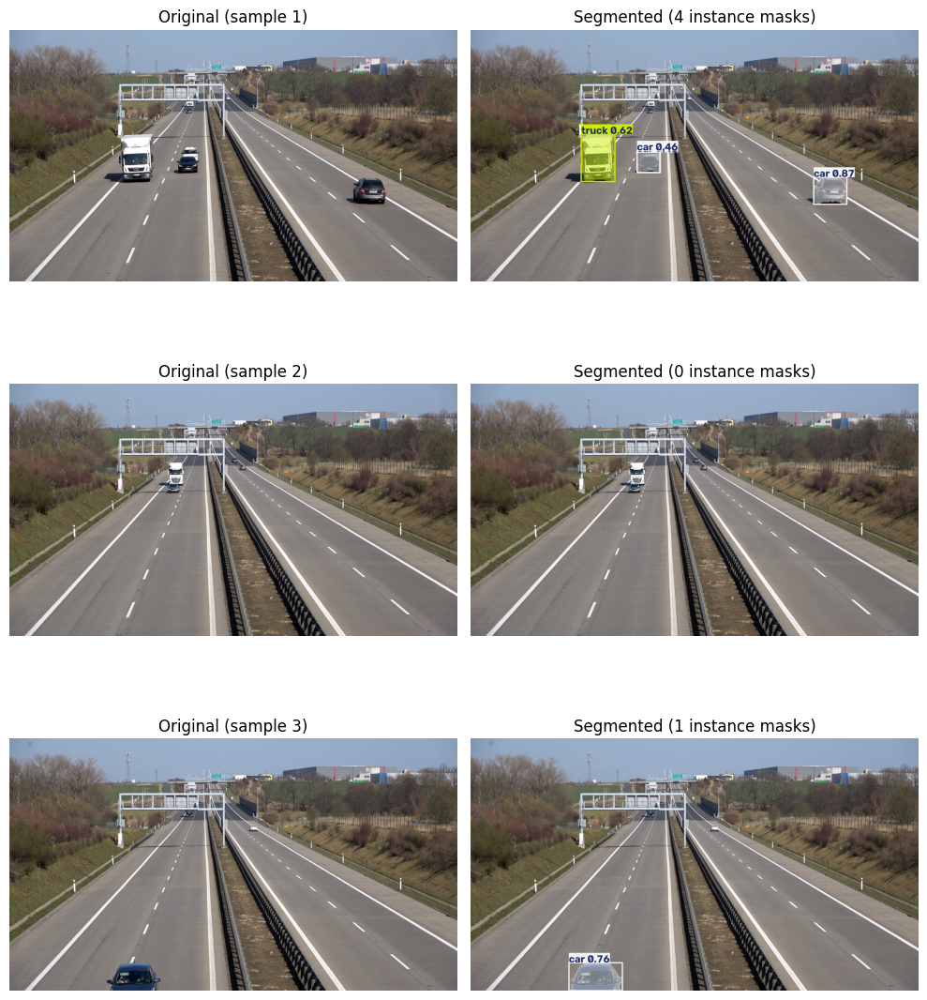

Segmented 3 sample frames in 10.72 seconds
Saved to: segmentation_demo.png


In [8]:
SEGMENTATION_SAMPLE_FRAMES = 3   # how many evenly-spaced frames to run segmentation on
SEGMENTATION_CHART_PATH = "segmentation_demo.png"

seg_model = YOLO("yolo26n-seg.pt")   # separate pretrained model - downloads automatically (~6 MB)

cap_seg = cv2.VideoCapture(LOCAL_VIDEO_PATH)
total_frames = int(cap_seg.get(cv2.CAP_PROP_FRAME_COUNT)) or 1
sample_indices = np.linspace(0, max(total_frames - 1, 0), SEGMENTATION_SAMPLE_FRAMES, dtype=int)

seg_frames = []
for idx in sample_indices:
    cap_seg.set(cv2.CAP_PROP_POS_FRAMES, int(idx))
    ret, frame = cap_seg.read()
    if ret:
        seg_frames.append(frame)
cap_seg.release()

if not seg_frames:
    print("Could not read any frames for the segmentation demo.")
else:
    t0 = time.time()
    fig, axes = plt.subplots(len(seg_frames), 2, figsize=(10, 4 * len(seg_frames)))
    if len(seg_frames) == 1:
        axes = axes.reshape(1, 2)

    for i, frame in enumerate(seg_frames):
        seg_results = seg_model.predict(frame, conf=CONF_THRESHOLD, classes=CLASSES_TO_COUNT, verbose=False)
        r = seg_results[0]
        annotated = r.plot()  # Ultralytics' own built-in mask + box visualization

        axes[i, 0].imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
        axes[i, 0].set_title(f"Original (sample {i + 1})")
        axes[i, 0].axis("off")

        n_masks = 0 if r.masks is None else len(r.masks.data)
        axes[i, 1].imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
        axes[i, 1].set_title(f"Segmented ({n_masks} instance masks)")
        axes[i, 1].axis("off")

    fig.tight_layout()
    fig.savefig(SEGMENTATION_CHART_PATH, dpi=110)
    plt.show()
    print(f"Segmented {len(seg_frames)} sample frames in {time.time() - t0:.2f} seconds")
    print(f"Saved to: {SEGMENTATION_CHART_PATH}")

## Presenting This as a University-Level Project

**Framing:** this is an *"Intelligent Traffic & Safety Analytics System"* — a full perception-to-insight pipeline, not a single object counter. What makes it substantial is the layered architecture, not model size.

**What to emphasize**
- **Architecture over accuracy.** Walk through the pipeline stages as a system diagram: Input → YOLO26n Detection → ByteTrack Association → Analytics Layer → Anomaly Layer → Dashboard. Each stage in this notebook maps to one section.
- **The analytics and anomaly layers are the original engineering.** The detector is pretrained, but the counting rules, the three anomaly detectors (wrong-way, loitering, stopped), and the heatmap accumulator were all designed and implemented on top of its raw output — that is the actual project content.
- **Justify "no training" as a deliberate, standard choice**, not a shortcut: using a pretrained detector via transfer learning is exactly how real-world CV systems are built; the contribution here is the decision layer above it.
- **Bring concrete artifacts**, not just a live run: `dashboard.png`, the two CSV logs, `classifier_training.png`, and a short clip of `output_analyzed.mp4` all work directly in a report or slide deck, and remove any dependency on a live demo going perfectly.
- **Section 6 answers "where's the actual training?"** directly, if asked: a real loss curve and a held-out test score exist alongside the rule-based system, deliberately scoped small enough to stay fast.
- **Section 7 answers "where's the segmentation?"** — a second, independently-loaded deep learning model (YOLO26n-seg), deliberately kept separate from the main pipeline so the (already-verified) tracking loop stays exactly as fast and reliable as before.
- **State limitations openly** (below) — acknowledging trade-offs reads as rigor in a defense, not weakness.

**Suggested report structure:** Problem statement → System architecture diagram → Pipeline walkthrough (one slide per stage) → Dashboard results → Limitations & future work (e.g., camera calibration for true speed, zone-based occupancy, a learned re-identification model for multi-camera tracking).

## Notes & Limitations

- Counting and anomaly detection both rely on tracking IDs staying stable; heavy occlusion or a very crowded scene can cause ID switches, which may affect all three anomaly rules as well as the crossing counts.
- "Stopped" detection uses pixel displacement, not real-world speed — without camera calibration (a known reference distance in the scene), speeds are relative, not in km/h or mph.
- "Wrong-way" detection needs a real majority direction to compare against; it stays silent until `WRONG_WAY_MIN_BASELINE_CROSSINGS` crossings have happened, so very short clips may show no wrong-way flags even if one occurred early on.
- The heatmap's colored overlay is redrawn every `HEATMAP_UPDATE_EVERY` frames rather than every frame, purely for CPU performance; the saved final heatmap is unaffected.
- The sample clips (`VIDEO_SOURCE_MODE = "sample"`) are third-party demo assets provided by Roboflow/Supervision for exactly this kind of tutorial use, not original footage — worth a one-line credit in a report ("demo video courtesy of the Supervision project, roboflow.com") if this footage appears in a submission.
- All outputs (`output_analyzed.mp4`, both CSVs, `heatmap_final.png`, `dashboard.png`) are saved after one run — nothing needs to be re-run to get a full result set.
- YOLO26n is Ultralytics' current-generation nano model (successor to YOLOv8n / YOLO11n), used here for its faster CPU inference; swapping in `"yolov8n.pt"` works with the exact same code if a specific model name is expected.
- The Section 6 classifier's labels come from YOLO26n's own predictions, not independent ground truth — it measures whether geometry and motion alone can *recover* the pretrained model's classification, not whether it beats it.
- Its training rows are frame-level samples from the same tracked objects, so nearby rows from one object are correlated rather than fully independent draws — a standard caveat for any per-frame-sampled dataset.
- Classes with few examples in a given clip (e.g. a single bus) will show weaker test accuracy than well-represented ones (e.g. cars) — a normal class-imbalance effect, and a reasonable thing to point out proactively rather than be asked about.
- Segmentation (Section 7) runs on `SEGMENTATION_SAMPLE_FRAMES` sample frames only, independently of the main tracking loop — it is a demonstration of the technique, not a replacement for the box-based counting/anomaly pipeline, and its results are not fed back into the counts, CSVs, or anomaly log.